This notebook structure can be cross-referenced alongside your file Unconfirmed 373077.txt.Installs dependencies without pulling conflicting stacks (--no-deps), including facenet-pytorch and kornia.   Forces reinstallation of a specific Pillow version.   Imports required Python and PyTorch libraries and configures CUDA device settings.   Sets seeds for reproducibility and configures CUDA allocation to reduce fragmentation-related Out-Of-Memory (OOM) errors

In [1]:
# ============================================================
# CELL 1 — Installs & imports
# (Kaggle: make sure "Internet" is ON for this notebook, since
#  facenet-pytorch downloads VGGFace2 weights on first use, and
#  kornia is not preinstalled on the base Kaggle image.)
# ============================================================

# --no-deps avoids facenet-pytorch/kornia dragging in a conflicting
# torch/torchvision/numpy/Pillow stack on top of Kaggle's preinstalled
# ones (this was the cause of the PIL._util ImportError -- pip had
# silently downgraded torch/torchvision underneath the environment).
!pip install -q --no-deps kornia facenet-pytorch
!pip install -q "Pillow>=10.0,<11" --force-reinstall --no-deps

import os
import re
import glob
import random
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler
import torchvision.transforms as T

import kornia
from facenet_pytorch import InceptionResnetV1

print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Reduces fragmentation-related OOMs on long runs
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 46.3 MB/s eta 0:00:00
Torch: 2.10.0+cu128
CUDA available: True
GPU count: 2
  GPU 0: Tesla T4
  GPU 1: Tesla T4


Defines the BiSeNet architecture verbatim.   This explicit definition is required to correctly load the state_dict of the 79999_iter.pth checkpoint.

In [2]:
# ============================================================
# CELL 2 — BiSeNet architecture (verbatim, needed to load the
# 79999_iter.pth checkpoint's state_dict)
# ============================================================

class BasicBlock(nn.Module):
    def __init__(self, in_chan, out_chan, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_chan, out_chan, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_chan)
        self.conv2 = nn.Conv2d(out_chan, out_chan, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_chan)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = None
        if in_chan != out_chan or stride != 1:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_chan, out_chan, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_chan)
            )

    def forward(self, x):
        residual = self.conv1(x)
        residual = F.relu(self.bn1(residual))
        residual = self.conv2(residual)
        residual = self.bn2(residual)
        shortcut = x
        if self.downsample is not None:
            shortcut = self.downsample(x)
        out = shortcut + residual
        out = self.relu(out)
        return out


def create_layer_basic(in_chan, out_chan, bnum, stride=1):
    layers = [BasicBlock(in_chan, out_chan, stride=stride)]
    for _ in range(bnum - 1):
        layers.append(BasicBlock(out_chan, out_chan, stride=1))
    return nn.Sequential(*layers)


class Resnet18(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.layer1 = create_layer_basic(64, 64, bnum=2, stride=1)
        self.layer2 = create_layer_basic(64, 128, bnum=2, stride=2)
        self.layer3 = create_layer_basic(128, 256, bnum=2, stride=2)
        self.layer4 = create_layer_basic(256, 512, bnum=2, stride=2)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(self.bn1(x))
        x = self.maxpool(x)
        x = self.layer1(x)
        feat8 = self.layer2(x)
        feat16 = self.layer3(feat8)
        feat32 = self.layer4(feat16)
        return feat8, feat16, feat32


class ConvBNReLU(nn.Module):
    def __init__(self, in_chan, out_chan, ks=3, stride=1, padding=1):
        super().__init__()
        self.conv = nn.Conv2d(in_chan, out_chan, kernel_size=ks, stride=stride, padding=padding, bias=False)
        self.bn = nn.BatchNorm2d(out_chan)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = F.relu(x)
        return x


class BiSeNetOutput(nn.Module):
    def __init__(self, in_chan, mid_chan, n_classes):
        super().__init__()
        self.conv = ConvBNReLU(in_chan, mid_chan, ks=3, stride=1, padding=1)
        self.conv_out = nn.Conv2d(mid_chan, n_classes, kernel_size=1, bias=False)

    def forward(self, x):
        x = self.conv(x)
        x = self.conv_out(x)
        return x


class AttentionRefinementModule(nn.Module):
    def __init__(self, in_chan, out_chan):
        super().__init__()
        self.conv = ConvBNReLU(in_chan, out_chan, ks=3, stride=1, padding=1)
        self.conv_atten = nn.Conv2d(out_chan, out_chan, kernel_size=1, bias=False)
        self.bn_atten = nn.BatchNorm2d(out_chan)
        self.sigmoid_atten = nn.Sigmoid()

    def forward(self, x):
        feat = self.conv(x)
        atten = F.avg_pool2d(feat, feat.size()[2:])
        atten = self.conv_atten(atten)
        atten = self.bn_atten(atten)
        atten = self.sigmoid_atten(atten)
        out = torch.mul(feat, atten)
        return out


class ContextPath(nn.Module):
    def __init__(self):
        super().__init__()
        self.resnet = Resnet18()
        self.arm16 = AttentionRefinementModule(256, 128)
        self.arm32 = AttentionRefinementModule(512, 128)
        self.conv_head32 = ConvBNReLU(128, 128, ks=3, stride=1, padding=1)
        self.conv_head16 = ConvBNReLU(128, 128, ks=3, stride=1, padding=1)
        self.conv_avg = ConvBNReLU(512, 128, ks=1, stride=1, padding=0)

    def forward(self, x):
        H0, W0 = x.size()[2:]
        feat8, feat16, feat32 = self.resnet(x)
        H8, W8 = feat8.size()[2:]
        H16, W16 = feat16.size()[2:]
        H32, W32 = feat32.size()[2:]

        avg = F.avg_pool2d(feat32, feat32.size()[2:])
        avg = self.conv_avg(avg)
        avg_up = F.interpolate(avg, (H32, W32), mode='nearest')

        feat32_arm = self.arm32(feat32)
        feat32_sum = feat32_arm + avg_up
        feat32_up = F.interpolate(feat32_sum, (H16, W16), mode='nearest')
        feat32_up = self.conv_head32(feat32_up)

        feat16_arm = self.arm16(feat16)
        feat16_sum = feat16_arm + feat32_up
        feat16_up = F.interpolate(feat16_sum, (H8, W8), mode='nearest')
        feat16_up = self.conv_head16(feat16_up)

        return feat8, feat16_up, feat32_up


class FeatureFusionModule(nn.Module):
    def __init__(self, in_chan, out_chan):
        super().__init__()
        self.convblk = ConvBNReLU(in_chan, out_chan, ks=1, stride=1, padding=0)
        self.conv1 = nn.Conv2d(out_chan, out_chan // 4, kernel_size=1, stride=1, padding=0, bias=False)
        self.conv2 = nn.Conv2d(out_chan // 4, out_chan, kernel_size=1, stride=1, padding=0, bias=False)
        self.relu = nn.ReLU(inplace=True)
        self.sigmoid = nn.Sigmoid()

    def forward(self, fsp, fcp):
        fcat = torch.cat([fsp, fcp], dim=1)
        feat = self.convblk(fcat)
        atten = F.avg_pool2d(feat, feat.size()[2:])
        atten = self.conv1(atten)
        atten = self.relu(atten)
        atten = self.conv2(atten)
        atten = self.sigmoid(atten)
        feat_atten = torch.mul(feat, atten)
        feat_out = feat_atten + feat
        return feat_out


class BiSeNet(nn.Module):
    def __init__(self, n_classes=19):
        super().__init__()
        self.cp = ContextPath()
        self.ffm = FeatureFusionModule(256, 256)
        self.conv_out = BiSeNetOutput(256, 256, n_classes)
        self.conv_out16 = BiSeNetOutput(128, 64, n_classes)
        self.conv_out32 = BiSeNetOutput(128, 64, n_classes)

    def forward(self, x):
        H, W = x.size()[2:]
        feat_res8, feat_cp8, feat_cp16 = self.cp(x)
        feat_sp = feat_res8
        feat_fuse = self.ffm(feat_sp, feat_cp8)
        feat_out = self.conv_out(feat_fuse)
        feat_out16 = self.conv_out16(feat_cp8)
        feat_out32 = self.conv_out32(feat_cp16)

        feat_out = F.interpolate(feat_out, (H, W), mode='bilinear', align_corners=True)
        feat_out16 = F.interpolate(feat_out16, (H, W), mode='bilinear', align_corners=True)
        feat_out32 = F.interpolate(feat_out32, (H, W), mode='bilinear', align_corners=True)

        return (feat_out, feat_out16, feat_out32)


print("BiSeNet class defined.")

BiSeNet class defined.


Defines all Face-swap GAN architectural components.   Implements mask extraction, face cropping/pasting, AdaIN modules, and the generator structure.   Defines the patch discriminator, identity embedder (using VGGFace2), and identity loss functions.   Assembles the main FaceSwapPipeline module

In [3]:
# ============================================================
# CELL 3 — Face-swap GAN architecture
# (mask extraction, crop/composite pipeline, generator,
#  discriminator, identity loss)
# ============================================================

FACE_CLASS_IDS = [1, 2, 3, 4, 5, 6, 10, 11, 12, 13]


class BiSeNetMaskExtractor(nn.Module):
    def __init__(self, bisenet: nn.Module, dilate_px: int = 6, feather_px: int = 9):
        super().__init__()
        self.bisenet = bisenet
        self.bisenet.eval()
        for p in self.bisenet.parameters():
            p.requires_grad_(False)
        self.dilate_px = dilate_px
        self.feather_px = feather_px
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    @torch.no_grad()
    def forward(self, img: torch.Tensor) -> torch.Tensor:
        B, C, H, W = img.shape
        img_512 = F.interpolate(img, size=(512, 512), mode="bilinear", align_corners=False)
        img_norm = (img_512 - self.mean) / self.std

        logits, _, _ = self.bisenet(img_norm)
        parsing = logits.argmax(dim=1, keepdim=True)

        face_mask = torch.zeros_like(parsing, dtype=torch.float32)
        for cls_id in FACE_CLASS_IDS:
            face_mask = face_mask + (parsing == cls_id).float()
        face_mask = face_mask.clamp(0, 1)

        face_mask = F.interpolate(face_mask, size=(H, W), mode="bilinear", align_corners=False)

        if self.dilate_px > 0:
            k = self.dilate_px * 2 + 1
            kernel = torch.ones((k, k), device=img.device)
            face_mask = kornia.morphology.dilation(face_mask, kernel)

        if self.feather_px > 0:
            k = self.feather_px * 2 + 1
            face_mask = kornia.filters.gaussian_blur2d(
                face_mask, (k, k), (self.feather_px / 2.0, self.feather_px / 2.0)
            )

        return face_mask.clamp(0, 1)


def mask_to_bbox(mask: torch.Tensor, margin_ratio: float = 0.35):
    B, _, H, W = mask.shape
    boxes = []
    bin_mask = (mask > 0.5)
    for b in range(B):
        ys, xs = torch.where(bin_mask[b, 0])
        if len(ys) == 0:
            size = min(H, W)
            boxes.append((H // 2 - size // 2, W // 2 - size // 2, size))
            continue
        y0, y1 = ys.min().item(), ys.max().item()
        x0, x1 = xs.min().item(), xs.max().item()
        h, w = y1 - y0, x1 - x0
        size = int(max(h, w) * (1 + margin_ratio))
        size = max(size, 8)  # safety floor
        cy, cx = (y0 + y1) // 2, (x0 + x1) // 2
        top = max(0, min(H - size, cy - size // 2))
        left = max(0, min(W - size, cx - size // 2))
        size = min(size, H - top, W - left)
        boxes.append((top, left, size))
    return boxes


def crop_faces(img: torch.Tensor, boxes, out_size: int = 256) -> torch.Tensor:
    crops = []
    for b, (top, left, size) in enumerate(boxes):
        crop = img[b:b + 1, :, top:top + size, left:left + size]
        crop = F.interpolate(crop, size=(out_size, out_size), mode="bilinear", align_corners=False)
        crops.append(crop)
    return torch.cat(crops, dim=0)


def paste_faces_back(full_img: torch.Tensor, face_crops: torch.Tensor, boxes) -> torch.Tensor:
    out = full_img.clone()
    for b, (top, left, size) in enumerate(boxes):
        resized = F.interpolate(face_crops[b:b + 1], size=(size, size), mode="bilinear", align_corners=False)
        out[b:b + 1, :, top:top + size, left:left + size] = resized
    return out


class AdaIN(nn.Module):
    def __init__(self, num_features: int, style_dim: int):
        super().__init__()
        self.norm = nn.InstanceNorm2d(num_features, affine=False)
        self.style_fc = nn.Linear(style_dim, num_features * 2)

    def forward(self, x, style):
        h = self.style_fc(style)
        gamma, beta = h.chunk(2, dim=1)
        gamma = gamma.unsqueeze(-1).unsqueeze(-1)
        beta = beta.unsqueeze(-1).unsqueeze(-1)
        return (1 + gamma) * self.norm(x) + beta


class ResBlockAdaIN(nn.Module):
    def __init__(self, channels: int, style_dim: int):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, 1, 1)
        self.adain1 = AdaIN(channels, style_dim)
        self.conv2 = nn.Conv2d(channels, channels, 3, 1, 1)
        self.adain2 = AdaIN(channels, style_dim)
        self.act = nn.LeakyReLU(0.2, inplace=True)

    def forward(self, x, style):
        residual = x
        x = self.act(self.adain1(self.conv1(x), style))
        x = self.adain2(self.conv2(x), style)
        return residual + x


class FaceSwapGenerator(nn.Module):
    def __init__(self, style_dim: int = 512, base_ch: int = 32):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(3, base_ch, 7, 1, 3),
            nn.InstanceNorm2d(base_ch),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base_ch, base_ch * 2, 4, 2, 1),
            nn.InstanceNorm2d(base_ch * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base_ch * 2, base_ch * 4, 4, 2, 1),
            nn.InstanceNorm2d(base_ch * 4),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base_ch * 4, base_ch * 8, 4, 2, 1),
            nn.InstanceNorm2d(base_ch * 8),
            nn.LeakyReLU(0.2, inplace=True),
        )
        self.bottleneck = nn.ModuleList([ResBlockAdaIN(base_ch * 8, style_dim) for _ in range(6)])

        self.dec_up1 = nn.ConvTranspose2d(base_ch * 8, base_ch * 4, 4, 2, 1)
        self.dec_norm1 = nn.InstanceNorm2d(base_ch * 4)
        self.dec_up2 = nn.ConvTranspose2d(base_ch * 4, base_ch * 2, 4, 2, 1)
        self.dec_norm2 = nn.InstanceNorm2d(base_ch * 2)
        self.dec_up3 = nn.ConvTranspose2d(base_ch * 2, base_ch, 4, 2, 1)
        self.dec_norm3 = nn.InstanceNorm2d(base_ch)
        self.act = nn.LeakyReLU(0.2, inplace=True)

        self.to_rgb = nn.Sequential(
            nn.Conv2d(base_ch, 3, 7, 1, 3),
            nn.Tanh(),
        )

    def forward(self, source_crop: torch.Tensor, identity_embed: torch.Tensor) -> torch.Tensor:
        feat = self.enc(source_crop)
        for block in self.bottleneck:
            feat = block(feat, identity_embed)
        x = self.act(self.dec_norm1(self.dec_up1(feat)))
        x = self.act(self.dec_norm2(self.dec_up2(x)))
        x = self.act(self.dec_norm3(self.dec_up3(x)))
        return self.to_rgb(x)


class PatchDiscriminator(nn.Module):
    def __init__(self, in_ch: int = 3, base_ch: int = 64):
        super().__init__()

        def block(in_c, out_c, norm=True):
            layers = [nn.Conv2d(in_c, out_c, 4, 2, 1)]
            if norm:
                layers.append(nn.InstanceNorm2d(out_c))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *block(in_ch, base_ch, norm=False),
            *block(base_ch, base_ch * 2),
            *block(base_ch * 2, base_ch * 4),
            *block(base_ch * 4, base_ch * 8),
            nn.Conv2d(base_ch * 8, 1, 4, 1, 1),
        )

    def forward(self, x):
        return self.model(x)


class IdentityEmbedder(nn.Module):
    """
    Wraps facenet-pytorch's InceptionResnetV1 (VGGFace2-pretrained) as
    a frozen 512-dim identity embedder -- our ArcFace-style stand-in.
    Expects input in [-1, 1], resizes internally to 160x160.
    """

    def __init__(self):
        super().__init__()
        self.net = InceptionResnetV1(pretrained="vggface2").eval()
        for p in self.net.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def _embed_nograd(self, x):
        x = F.interpolate(x, size=(160, 160), mode="bilinear", align_corners=False)
        return self.net(x)

    def forward(self, x, allow_grad: bool = False):
        x160 = F.interpolate(x, size=(160, 160), mode="bilinear", align_corners=False)
        if allow_grad:
            return self.net(x160)
        with torch.no_grad():
            return self.net(x160)


class IdentityLoss(nn.Module):
    def __init__(self, identity_embedder: IdentityEmbedder):
        super().__init__()
        self.embedder = identity_embedder

    def forward(self, generated_face: torch.Tensor, target_face: torch.Tensor) -> torch.Tensor:
        target_embed = self.embedder(target_face, allow_grad=False)
        gen_embed = self.embedder(generated_face, allow_grad=True)
        return 1 - F.cosine_similarity(gen_embed, target_embed, dim=1).mean()


def boundary_consistency_loss(composite, source, mask, feather_px: int = 9):
    k = feather_px * 2 + 1
    inner = kornia.morphology.erosion(mask, torch.ones((k, k), device=mask.device))
    ring = (mask - inner).clamp(0, 1)
    return F.l1_loss(composite * ring, source * ring)


class FaceSwapPipeline(nn.Module):
    """
    source_img, target_img: (B,3,H,W) in [0,1].
    target_face_crop: (B,3,h,w) in [0,1] -- pre-cropped target FACE
      (we crop this once in the Dataset using BiSeNet on target too,
      see Cell 5's dataset class).
    """

    def __init__(self, bisenet: nn.Module, identity_embedder: IdentityEmbedder,
                 crop_size: int = 256, style_dim: int = 512):
        super().__init__()
        self.mask_extractor = BiSeNetMaskExtractor(bisenet)
        self.identity_embedder = identity_embedder
        self.generator = FaceSwapGenerator(style_dim=style_dim)
        self.crop_size = crop_size

    def forward(self, source_img: torch.Tensor, target_face_crop: torch.Tensor):
        mask = self.mask_extractor(source_img)
        boxes = mask_to_bbox(mask)

        source_crop = crop_faces(source_img, boxes, self.crop_size)
        target_crop = F.interpolate(target_face_crop, size=(self.crop_size, self.crop_size),
                                     mode="bilinear", align_corners=False)

        source_crop_norm = source_crop * 2 - 1
        target_crop_norm = target_crop * 2 - 1

        identity_embed = self.identity_embedder(target_crop_norm, allow_grad=False)

        gen_face = self.generator(source_crop_norm, identity_embed)
        gen_face_01 = (gen_face + 1) / 2

        full_res_with_face = paste_faces_back(source_img, gen_face_01, boxes)
        composite = mask * full_res_with_face + (1 - mask) * source_img

        return composite, mask, source_crop, gen_face_01, target_crop        


print("Architecture defined: BiSeNetMaskExtractor, FaceSwapGenerator, PatchDiscriminator, IdentityEmbedder, FaceSwapPipeline")

Architecture defined: BiSeNetMaskExtractor, FaceSwapGenerator, PatchDiscriminator, IdentityEmbedder, FaceSwapPipeline


Defines directories for flickr_deepfake and ffhq datasets.   Sets full image sizes and network crop sizes.   Configures the dataset loader for paired images with an optional swapped image supervision signal.

In [4]:
# ============================================================
# CELL 4 — Dataset
#
# flickr_deepfake/{source}_{target}.jpg   e.g. 200_3000.jpg
# ffhq/{00200}.png, ffhq/{03000}.png       (5-digit zero-padded)
#
# We use the existing swapped image ONLY as an optional pixel-level
# auxiliary supervision signal (it shows roughly what "source
# structure + target identity" should look like, produced by
# whatever method built that dataset) -- NOT as strict ground
# truth, since our architecture/losses are self-supervised via
# identity + reconstruction + adversarial. If you'd rather ignore
# it entirely, set `use_swapped_as_aux=False` below.
# ============================================================

SWAPPED_DIR = "/kaggle/input/datasets/syedajannatulnaim/deepfakeface-swapped-images-using-ffhq-dataset/flickr_deepfake"
FFHQ_DIR = "/kaggle/input/datasets/arnaud58/flickrfaceshq-dataset-ffhq"

IMG_SIZE = 512          # working resolution for full images (source/composite space)
CROP_SIZE = 256         # generator's fixed working resolution (per our architecture discussion)


def ffhq_path(idx: int) -> str:
    """idx like 200 or 3000 -> zero-padded 5-digit FFHQ filename."""
    fname = f"{idx:05d}.png"
    return os.path.join(FFHQ_DIR, fname)


def parse_pair_filename(fname: str):
    """'200_3000.jpg' -> (200, 3000)"""
    stem = os.path.splitext(os.path.basename(fname))[0]
    src_str, tgt_str = stem.split("_")
    return int(src_str), int(tgt_str)


class FaceSwapPairDataset(Dataset):
    def __init__(self, swapped_dir: str = SWAPPED_DIR, ffhq_dir: str = FFHQ_DIR,
                 img_size: int = IMG_SIZE, use_swapped_as_aux: bool = True,
                 limit: int = None):
        self.ffhq_dir = ffhq_dir
        self.img_size = img_size
        self.use_swapped_as_aux = use_swapped_as_aux

        all_files = sorted(glob.glob(os.path.join(swapped_dir, "*.jpg")) +
                            glob.glob(os.path.join(swapped_dir, "*.jpeg")) +
                            glob.glob(os.path.join(swapped_dir, "*.png")))

        # Filter to pairs whose both FFHQ source images actually exist on disk
        # (defensive -- avoids a crash mid-epoch on a missing file).
        valid = []
        for f in all_files:
            try:
                src_idx, tgt_idx = parse_pair_filename(f)
            except ValueError:
                continue
            if os.path.exists(ffhq_path(src_idx)) and os.path.exists(ffhq_path(tgt_idx)):
                valid.append((f, src_idx, tgt_idx))

        if limit is not None:
            valid = valid[:limit]

        self.samples = valid
        print(f"FaceSwapPairDataset: {len(self.samples)} valid pairs found "
              f"(out of {len(all_files)} files in swapped dir).")

        self.transform = T.Compose([
            T.Resize((img_size, img_size)),
            T.ToTensor(),  # -> [0,1]
        ])

    def __len__(self):
        return len(self.samples)

    def _load(self, path: str) -> torch.Tensor:
        with Image.open(path) as img:
            return self.transform(img.convert("RGB"))

    def __getitem__(self, i):
        swapped_path, src_idx, tgt_idx = self.samples[i]

        source_img = self._load(ffhq_path(src_idx))    # (3, H, W) in [0,1]
        target_img = self._load(ffhq_path(tgt_idx))

        item = {
            "source": source_img,
            "target": target_img,
            "src_idx": src_idx,
            "tgt_idx": tgt_idx,
        }

        if self.use_swapped_as_aux:
            item["swapped_aux"] = self._load(swapped_path)

        return item


print("Dataset class defined: FaceSwapPairDataset")

Dataset class defined: FaceSwapPairDataset


Verifies GPU availability and sets up multi-GPU usage via DataParallel.   Instantiates the previously defined models (BiSeNet, Embedder, Generator, Discriminator) and sends them to the appropriate compute device.   Freezes submodules correctly to prevent unintended training behavior. 

In [5]:
# ============================================================
# CELL 5 — Build models, load BiSeNet weights, set up single-GPU
# ============================================================

CHECKPOINT_PATH = "/kaggle/input/models/nilanjansaha123/the-7999/pytorch/default/1/79999_iter.pth"

assert torch.cuda.is_available(), "No GPU found!"
device = torch.device("cuda:0")

print("Using Single GPU setup to prevent Host RAM explosion.")

# ---- Load frozen BiSeNet (segmentation prior) ----
bisenet = BiSeNet(n_classes=19)
state_dict = torch.load(CHECKPOINT_PATH, map_location="cpu")
bisenet.load_state_dict(state_dict)
bisenet.eval()
for p in bisenet.parameters():
    p.requires_grad_(False)
bisenet = bisenet.to(device)

# ---- Frozen identity embedder (VGGFace2 InceptionResnetV1) ----
identity_embedder = IdentityEmbedder().to(device)

# ---- Trainable pipeline (generator + frozen submodules inside it) ----
pipeline = FaceSwapPipeline(bisenet, identity_embedder, crop_size=CROP_SIZE, style_dim=512).to(device)

# ---- Discriminator ----
discriminator = PatchDiscriminator().to(device)

# ---- Identity loss module (thin wrapper, uses identity_embedder) ----
identity_loss_fn = IdentityLoss(identity_embedder).to(device)

target_mask_extractor = BiSeNetMaskExtractor(bisenet).to(device)

def get_target_face_crop(target_img: torch.Tensor, crop_size: int = CROP_SIZE) -> torch.Tensor:
    """target_img: (B,3,H,W) in [0,1] -> (B,3,crop_size,crop_size) face-only crop."""
    with torch.no_grad():
        mask = target_mask_extractor(target_img)
        boxes = mask_to_bbox(mask)
        crop = crop_faces(target_img, boxes, crop_size)
    return crop

n_params_gen = sum(p.numel() for p in pipeline.generator.parameters())
n_params_disc = sum(p.numel() for p in discriminator.parameters())
print(f"Generator params: {n_params_gen / 1e6:.2f}M")
print(f"Discriminator params: {n_params_disc / 1e6:.2f}M")

Using Single GPU setup to prevent Host RAM explosion.


  0%|          | 0.00/107M [00:00<?, ?B/s]

Generator params: 11.62M
Discriminator params: 2.76M


Configures the DataLoader with conservative total batches across GPUs to prevent memory exhaustion.   Uses dropped final uneven batches (drop_last=True) and persistent workers to optimize loading times. 

In [6]:
# ============================================================
# CELL 6 — DataLoader
# ============================================================

BATCH_SIZE = 4             # Halved from 8 to fit the single GPU capacity
NUM_WORKERS = 2            # Reduced to minimize host RAM footprint
LIMIT_SAMPLES = None       

dataset = FaceSwapPairDataset(use_swapped_as_aux=True, limit=LIMIT_SAMPLES)

dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,          
    persistent_workers=False, # Set to False to stop memory accumulation across batches
)

print(f"Dataset size: {len(dataset)} | Batches/epoch: {len(dataloader)}")

FaceSwapPairDataset: 111016 valid pairs found (out of 111016 files in swapped dir).
Dataset size: 111016 | Batches/epoch: 27754


Sets up distinct Adam optimizers filtered to strictly target the unfrozen parameters within the Generator and Discriminator.   Defines Automatic Mixed Precision (AMP) scalers for memory-efficient training scaling.   Defines core loss function weights (Identity, Reconstruction, Adversarial, Auxiliary, Boundary).  

In [7]:
# ============================================================
# CELL 7 — Optimizers, AMP scalers, checkpoint dir
# ============================================================

LR_G = 2e-4
LR_D = 2e-4
BETA1, BETA2 = 0.5, 0.999

# NOTE: only the generator's parameters are trainable inside `pipeline`
# (mask_extractor and identity_embedder are frozen). Filtering by
# requires_grad keeps the optimizer from wasting state on frozen params
# and avoids accidentally "training" something we froze.
opt_g = torch.optim.Adam(
    filter(lambda p: p.requires_grad, pipeline.parameters()),
    lr=LR_G, betas=(BETA1, BETA2),
)
opt_d = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, BETA2))

# Mixed precision -- roughly halves activation memory and speeds up
# conv-heavy workloads substantially on T4 (which has real fp16 tensor
# cores). Separate scalers for G and D since they're stepped separately.
scaler_g = GradScaler()
scaler_d = GradScaler()

CHECKPOINT_DIR = "/kaggle/working/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

LAMBDA_ID = 10.0
LAMBDA_REC = 5.0
LAMBDA_ADV = 1.0
LAMBDA_AUX = 3.0          # weight for the optional swapped-image aux loss
LAMBDA_BOUNDARY = 5.0

print("Optimizers and AMP scalers ready.")

Optimizers and AMP scalers ready.


/tmp/ipykernel_23/465765673.py:22: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_g = GradScaler()
/tmp/ipykernel_23/465765673.py:23: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_d = GradScaler()


Implements epoch visualization metrics via torchvision.utils and matplotlib.   Extracts predictions through evaluating batch targets to produce visual grids comparing Source, Target, Generated composite, and optional pseudo-GT auxiliary targets.   

In [8]:
# ============================================================
# CELL 9 — Visualization
# ============================================================

import torchvision.utils as vutils
import matplotlib.pyplot as plt

VIS_DIR = "/kaggle/working/visuals"
os.makedirs(VIS_DIR, exist_ok=True)

N_VIS_SAMPLES = 4  

@torch.no_grad()
def save_epoch_visuals(epoch: int, dataloader, pipeline_model, n_samples: int = N_VIS_SAMPLES):
    pipeline_model.eval()

    batch = next(iter(dataloader))
    source_img = batch["source"][:n_samples].to(device)
    target_img = batch["target"][:n_samples].to(device)
    swapped_aux = batch.get("swapped_aux")
    if swapped_aux is not None:
        swapped_aux = swapped_aux[:n_samples].to(device)

    target_face_crop = get_target_face_crop(target_img)

    with torch.amp.autocast("cuda"):
        composite_out, mask_out, source_crop_out, gen_face_out, target_crop_out = pipeline_model(source_img, target_face_crop)

    composite = composite_out.float().clamp(0, 1)
    gen_face = gen_face_out.float().clamp(0, 1)
    source_crop = source_crop_out.float().clamp(0, 1)
    target_crop = target_crop_out.float().clamp(0, 1)

    if swapped_aux is not None:
        aux_boxes = mask_to_bbox(mask_out)
        aux_crop = crop_faces(swapped_aux, aux_boxes, CROP_SIZE).clamp(0, 1)
    else:
        aux_crop = torch.zeros_like(gen_face)

    # ---- Full-resolution grid ----
    full_rows = []
    for i in range(n_samples):
        row = torch.stack([
            source_img[i].cpu(),
            target_img[i].cpu(),
            composite[i].cpu(),
            (swapped_aux[i].cpu() if swapped_aux is not None else torch.zeros_like(source_img[i].cpu())),
        ])
        full_rows.append(row)
    full_grid_tensor = torch.cat(full_rows, dim=0) 
    full_grid = vutils.make_grid(full_grid_tensor, nrow=4, padding=4)

    # ---- Face-crop grid ----
    crop_rows = []
    for i in range(n_samples):
        row = torch.stack([
            source_crop[i].cpu(),
            target_crop[i].cpu(),
            gen_face[i].cpu(),
            aux_crop[i].cpu(),
        ])
        crop_rows.append(row)
    crop_grid_tensor = torch.cat(crop_rows, dim=0)
    crop_grid = vutils.make_grid(crop_grid_tensor, nrow=4, padding=4)

    # ---- Plot + save ----
    fig, axes = plt.subplots(2, 1, figsize=(14, 7 * n_samples / 2))

    axes[0].imshow(full_grid.permute(1, 2, 0).numpy())
    axes[0].set_title(f"Epoch {epoch} — Full image | Source / Target / Generated / Swapped-aux (pseudo-GT)")
    axes[0].axis("off")

    axes[1].imshow(crop_grid.permute(1, 2, 0).numpy())
    axes[1].set_title(f"Epoch {epoch} — Face crop | Source-crop / Target-crop / Gen-face / Aux-crop")
    axes[1].axis("off")

    plt.tight_layout()
    save_path = os.path.join(VIS_DIR, f"epoch_{epoch:03d}.png")
    plt.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"  [visuals saved: {save_path}]")
    pipeline_model.train()

print("Visualization function defined: save_epoch_visuals")

Visualization function defined: save_epoch_visuals


Contains the central epoch execution and forward pass loops.   Calculates model losses step-by-step through Generator and Discriminator steps utilizing backward pass scaling.   Integrates robust memory clearing via selective del and targeted garbage collection torch.cuda.empty_cache() every set number of steps to stop fragmentation.   Logs loss statuses and commits network weight checkpoints periodically.

Epoch 0/4:   0%|          | 0/27754 [00:00<?, ?step/s]

[epoch 0 step 0/27754] [ETA: Calculating...] id=1.0066 rec=0.5183 adv=2.1496 aux=0.2576 boundary=0.0077 d=1.1604 | GPU0 alloc=0.31GB reserved=3.16GB | Host RAM=2.38GB
[epoch 0 step 50/27754] [ETA: 02:03:47] id=0.9627 rec=0.3908 adv=0.6107 aux=0.1955 boundary=0.0059 d=0.0833 | GPU0 alloc=0.43GB reserved=3.21GB | Host RAM=2.50GB
[epoch 0 step 100/27754] [ETA: 02:06:04] id=0.8020 rec=0.3315 adv=0.7658 aux=0.1823 boundary=0.0062 d=0.0460 | GPU0 alloc=0.43GB reserved=3.21GB | Host RAM=2.50GB
[epoch 0 step 150/27754] [ETA: 02:06:13] id=0.8632 rec=0.3541 adv=0.9396 aux=0.1806 boundary=0.0072 d=0.0811 | GPU0 alloc=0.43GB reserved=3.21GB | Host RAM=2.50GB
[epoch 0 step 200/27754] [ETA: 02:48:51] id=0.9082 rec=0.3762 adv=1.2972 aux=0.1795 boundary=0.0060 d=0.0481 | GPU0 alloc=0.43GB reserved=3.52GB | Host RAM=2.50GB
[epoch 0 step 250/27754] [ETA: 02:04:39] id=0.9104 rec=0.3631 adv=0.5328 aux=0.1776 boundary=0.0069 d=0.0818 | GPU0 alloc=0.43GB reserved=3.52GB | Host RAM=2.50GB
[epoch 0 step 300/2

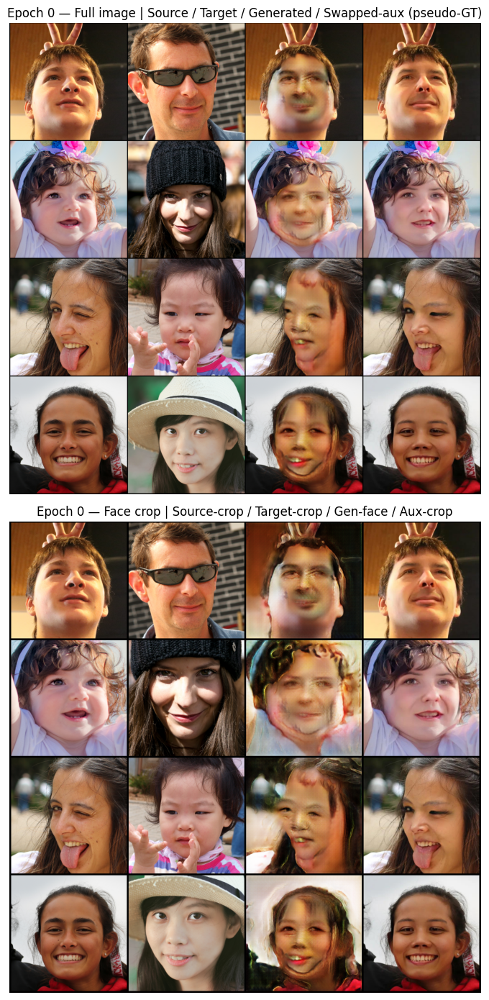

  [visuals saved: /kaggle/working/visuals/epoch_000.png]


Epoch 1/4:   0%|          | 0/27754 [00:00<?, ?step/s]

[epoch 1 step 0/27754] [ETA: Calculating...] id=0.2605 rec=0.2039 adv=0.9404 aux=0.1003 boundary=0.0041 d=0.0200 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.58GB
[epoch 1 step 50/27754] [ETA: 02:38:30] id=0.2077 rec=0.1921 adv=0.7072 aux=0.0976 boundary=0.0041 d=0.0322 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.63GB
[epoch 1 step 100/27754] [ETA: 02:23:10] id=0.1827 rec=0.1803 adv=0.8017 aux=0.0976 boundary=0.0039 d=0.0159 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.63GB
[epoch 1 step 150/27754] [ETA: 02:22:18] id=0.2892 rec=0.2062 adv=1.1010 aux=0.0997 boundary=0.0038 d=0.0095 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.63GB
[epoch 1 step 200/27754] [ETA: 02:22:21] id=0.1956 rec=0.2768 adv=0.8754 aux=0.1017 boundary=0.0044 d=0.0138 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.63GB
[epoch 1 step 250/27754] [ETA: 02:29:44] id=0.3485 rec=0.1923 adv=1.0981 aux=0.1036 boundary=0.0036 d=0.0155 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.63GB
[epoch 1 step 300/2

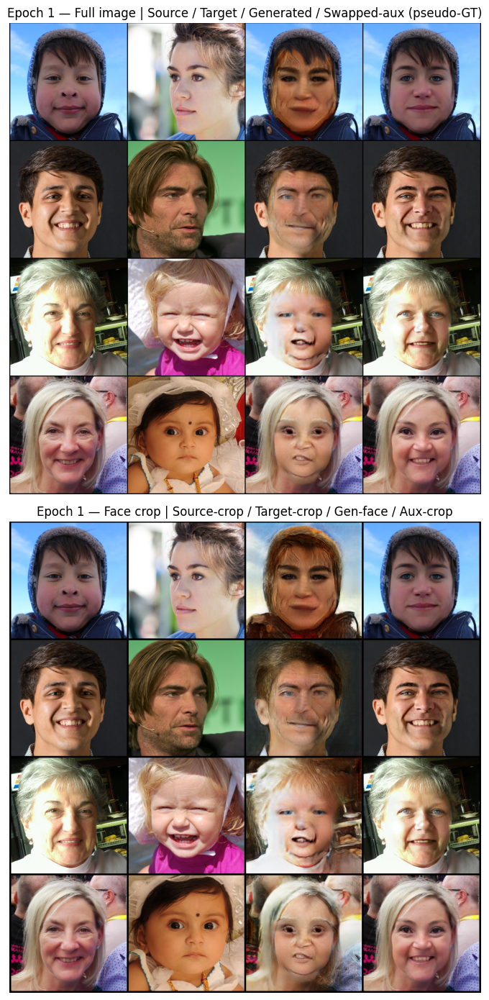

  [visuals saved: /kaggle/working/visuals/epoch_001.png]


Epoch 2/4:   0%|          | 0/27754 [00:00<?, ?step/s]

[epoch 2 step 0/27754] [ETA: Calculating...] id=0.1919 rec=0.1404 adv=0.4197 aux=0.0668 boundary=0.0035 d=0.0828 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.45GB
[epoch 2 step 50/27754] [ETA: 02:10:45] id=0.1852 rec=0.1469 adv=0.7331 aux=0.0817 boundary=0.0037 d=0.0453 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.45GB
[epoch 2 step 100/27754] [ETA: 02:12:00] id=0.1829 rec=0.2133 adv=1.1077 aux=0.0810 boundary=0.0048 d=0.0281 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.45GB
[epoch 2 step 150/27754] [ETA: 02:08:27] id=0.2920 rec=0.2074 adv=0.7480 aux=0.0836 boundary=0.0052 d=0.0467 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.45GB
[epoch 2 step 200/27754] [ETA: 02:10:11] id=0.1729 rec=0.1484 adv=0.2149 aux=0.0841 boundary=0.0033 d=0.1758 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.45GB
[epoch 2 step 250/27754] [ETA: 02:09:41] id=0.1471 rec=0.1568 adv=0.7075 aux=0.0846 boundary=0.0037 d=0.0579 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.45GB
[epoch 2 step 300/2

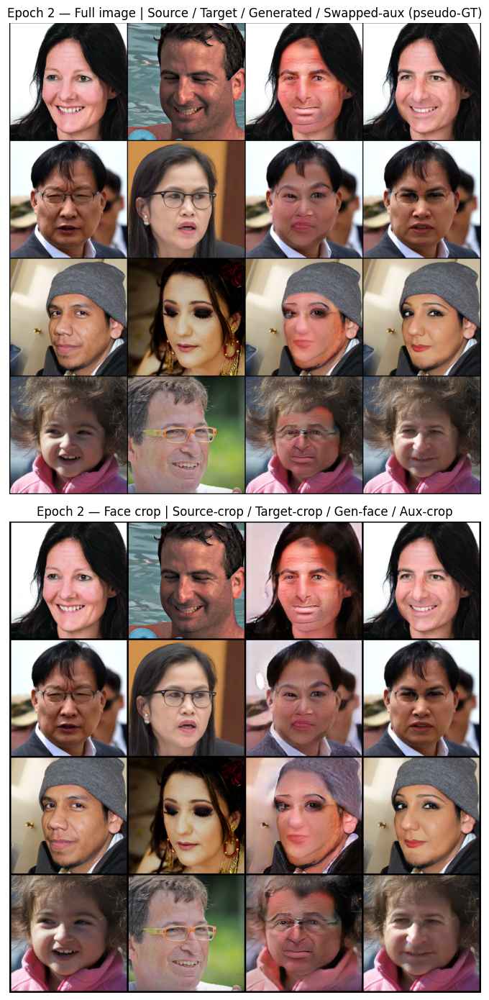

  [visuals saved: /kaggle/working/visuals/epoch_002.png]


Epoch 3/4:   0%|          | 0/27754 [00:00<?, ?step/s]

[epoch 3 step 0/27754] [ETA: Calculating...] id=0.1935 rec=0.1742 adv=0.6155 aux=0.0838 boundary=0.0040 d=0.0437 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.50GB
[epoch 3 step 50/27754] [ETA: 02:13:00] id=0.1817 rec=0.1677 adv=0.6555 aux=0.0794 boundary=0.0036 d=0.0659 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.48GB
[epoch 3 step 100/27754] [ETA: 02:15:15] id=0.1718 rec=0.1776 adv=1.2880 aux=0.0810 boundary=0.0041 d=0.0327 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.48GB
[epoch 3 step 150/27754] [ETA: 02:15:12] id=0.1493 rec=0.1494 adv=0.7463 aux=0.0800 boundary=0.0036 d=0.1142 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.48GB
[epoch 3 step 200/27754] [ETA: 02:09:30] id=0.1882 rec=0.1578 adv=1.1429 aux=0.0814 boundary=0.0038 d=0.0517 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.48GB
[epoch 3 step 250/27754] [ETA: 02:09:26] id=0.1926 rec=0.1420 adv=0.8216 aux=0.0813 boundary=0.0034 d=0.0472 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.48GB
[epoch 3 step 300/2

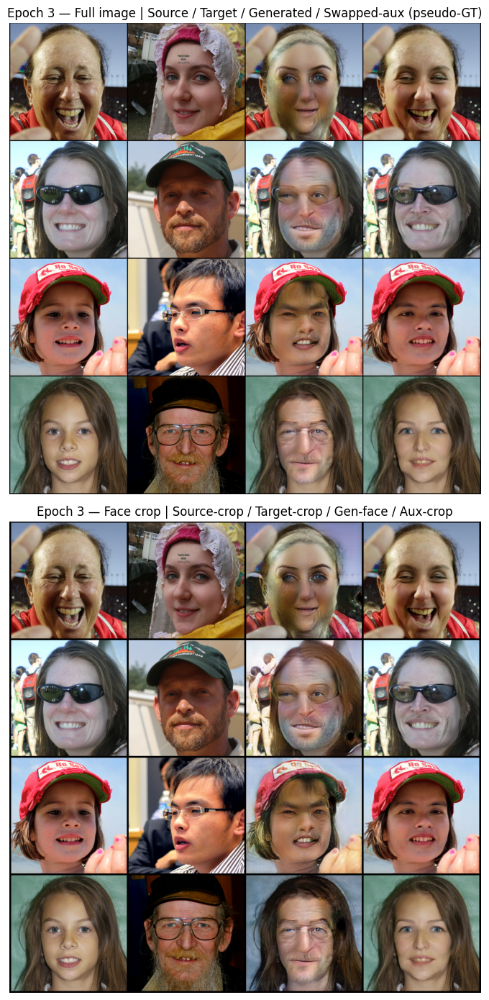

  [visuals saved: /kaggle/working/visuals/epoch_003.png]


Epoch 4/4:   0%|          | 0/27754 [00:00<?, ?step/s]

[epoch 4 step 0/27754] [ETA: Calculating...] id=0.1312 rec=0.1553 adv=0.7252 aux=0.0730 boundary=0.0033 d=0.0400 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.45GB
[epoch 4 step 50/27754] [ETA: 02:12:05] id=0.1651 rec=0.1511 adv=0.7303 aux=0.0769 boundary=0.0032 d=0.0395 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.45GB
[epoch 4 step 100/27754] [ETA: 02:11:57] id=0.1622 rec=0.1713 adv=0.7892 aux=0.0753 boundary=0.0036 d=0.0257 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.45GB
[epoch 4 step 150/27754] [ETA: 02:11:51] id=0.1756 rec=0.1592 adv=0.7456 aux=0.0755 boundary=0.0038 d=0.0392 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.45GB
[epoch 4 step 200/27754] [ETA: 02:12:18] id=0.2037 rec=0.1445 adv=0.6062 aux=0.0753 boundary=0.0032 d=0.0605 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.45GB
[epoch 4 step 250/27754] [ETA: 02:14:00] id=0.2151 rec=0.1541 adv=0.6337 aux=0.0752 boundary=0.0028 d=0.0764 | GPU0 alloc=0.43GB reserved=3.55GB | Host RAM=2.45GB
[epoch 4 step 300/2

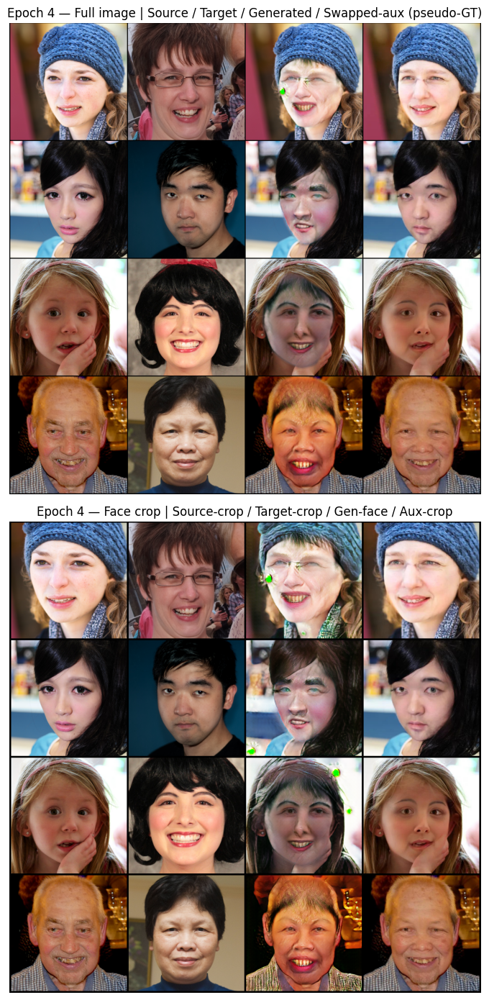

  [visuals saved: /kaggle/working/visuals/epoch_004.png]
Training complete.


In [9]:
# ============================================================
# CELL 8 — Training loop
# ============================================================

import time
import gc
import psutil
from tqdm.auto import tqdm

NUM_EPOCHS = 5
LOG_EVERY = 50
CKPT_EVERY_STEPS = 10000
EMPTY_CACHE_EVERY = 200
GRAD_CLIP_NORM = 5.0

global_step = 0
_proc = psutil.Process(os.getpid())

def save_checkpoint(tag: str):
    torch.save({
        "generator": pipeline.generator.state_dict(),
        "discriminator": discriminator.state_dict(),
        "opt_g": opt_g.state_dict(),
        "opt_d": opt_d.state_dict(),
        "global_step": global_step,
    }, os.path.join(CHECKPOINT_DIR, f"ckpt_{tag}.pt"))
    print(f"  [checkpoint saved: ckpt_{tag}.pt]")

for epoch in range(NUM_EPOCHS):
    epoch_start = time.time()
    running = {"id": 0.0, "rec": 0.0, "adv": 0.0, "aux": 0.0, "boundary": 0.0, "d": 0.0}
    n_batches = 0

    pbar = tqdm(
        enumerate(dataloader),
        total=len(dataloader),
        desc=f"Epoch {epoch}/{NUM_EPOCHS - 1}",
        unit="step",
        dynamic_ncols=True,
    )

    for step, batch in pbar:
        source_img = batch["source"].to(device, non_blocking=True)
        target_img = batch["target"].to(device, non_blocking=True)
        swapped_aux = batch.get("swapped_aux")
        if swapped_aux is not None:
            swapped_aux = swapped_aux.to(device, non_blocking=True)

        target_face_crop = get_target_face_crop(target_img)

        with torch.amp.autocast("cuda"):
            composite, mask, source_crop, gen_face_01, target_crop = pipeline(source_img, target_face_crop)

            gen_face = gen_face_01 * 2 - 1
            target_crop_n = target_crop * 2 - 1
            source_crop_n = source_crop * 2 - 1

            l_id = identity_loss_fn(gen_face, target_crop_n)
            l_rec = F.l1_loss(gen_face, source_crop_n)

            pred_fake = discriminator(gen_face)
            l_adv = F.mse_loss(pred_fake, torch.ones_like(pred_fake))

            l_boundary = boundary_consistency_loss(composite, source_img, mask)

            if swapped_aux is not None:
                with torch.no_grad():
                    aux_mask = pipeline.mask_extractor(source_img)
                    aux_boxes = mask_to_bbox(aux_mask)
                aux_crop = crop_faces(swapped_aux, aux_boxes, CROP_SIZE)
                l_aux = F.l1_loss(gen_face_01, aux_crop)
            else:
                l_aux = torch.tensor(0.0, device=device)

            g_loss = (
                LAMBDA_ID * l_id
                + LAMBDA_REC * l_rec
                + LAMBDA_ADV * l_adv
                + LAMBDA_AUX * l_aux
                + LAMBDA_BOUNDARY * l_boundary
            )

        opt_g.zero_grad(set_to_none=True)
        scaler_g.scale(g_loss).backward()
        scaler_g.unscale_(opt_g)
        torch.nn.utils.clip_grad_norm_(
            filter(lambda p: p.requires_grad, pipeline.parameters()), GRAD_CLIP_NORM
        )
        scaler_g.step(opt_g)
        scaler_g.update()

        with torch.amp.autocast("cuda"):
            real_crop = source_crop_n.detach()
            fake_crop = gen_face.detach()
            pred_real = discriminator(real_crop)
            pred_fake_d = discriminator(fake_crop)
            d_loss = 0.5 * (
                F.mse_loss(pred_real, torch.ones_like(pred_real))
                + F.mse_loss(pred_fake_d, torch.zeros_like(pred_fake_d))
            )

        opt_d.zero_grad(set_to_none=True)
        scaler_d.scale(d_loss).backward()
        scaler_d.step(opt_d)
        scaler_d.update()

        id_val = l_id.item()
        rec_val = l_rec.item()
        adv_val = l_adv.item()
        aux_val = l_aux.item() if torch.is_tensor(l_aux) else l_aux
        boundary_val = l_boundary.item()
        d_val = d_loss.item()

        running["id"] += id_val
        running["rec"] += rec_val
        running["adv"] += adv_val
        running["aux"] += aux_val
        running["boundary"] += boundary_val
        running["d"] += d_val
        n_batches += 1
        global_step += 1

        pbar.set_postfix({
            "id": f"{id_val:.3f}",
            "rec": f"{rec_val:.3f}",
            "adv": f"{adv_val:.3f}",
            "d": f"{d_val:.3f}",
        })

        # Calculate live ETA using tqdm metadata
        format_dict = pbar.format_dict
        rate = format_dict.get("rate")
        if rate and rate > 0:
            remaining_sec = (format_dict["total"] - format_dict["n"]) / rate
            eta_str = time.strftime('%H:%M:%S', time.gmtime(remaining_sec))
        else:
            eta_str = "Calculating..."

        del (composite, mask, source_crop, gen_face_01, target_crop, gen_face, 
             target_crop_n, source_crop_n, pred_fake, pred_real,
             pred_fake_d, source_img, target_img, target_face_crop, batch,
             l_id, l_rec, l_adv, l_boundary, l_aux, g_loss, d_loss)
        
        if swapped_aux is not None:
            del swapped_aux, aux_crop, aux_mask, aux_boxes

        if global_step % EMPTY_CACHE_EVERY == 0:
            gc.collect()
            torch.cuda.empty_cache()

        if step % LOG_EVERY == 0:
            mem_alloc = torch.cuda.memory_allocated(0) / 1e9
            mem_reserved = torch.cuda.memory_reserved(0) / 1e9
            host_ram_gb = _proc.memory_info().rss / 1e9
            pbar.write(
                f"[epoch {epoch} step {step}/{len(dataloader)}] [ETA: {eta_str}] "
                f"id={id_val:.4f} rec={rec_val:.4f} adv={adv_val:.4f} "
                f"aux={running['aux']/n_batches:.4f} boundary={boundary_val:.4f} "
                f"d={d_val:.4f} | GPU0 alloc={mem_alloc:.2f}GB reserved={mem_reserved:.2f}GB "
                f"| Host RAM={host_ram_gb:.2f}GB"
            )

        if global_step % CKPT_EVERY_STEPS == 0:
            save_checkpoint(f"step{global_step}")

    pbar.close()

    epoch_time = time.time() - epoch_start
    print(f"=== Epoch {epoch} done in {epoch_time/60:.1f} min | "
          f"avg id={running['id']/n_batches:.4f} rec={running['rec']/n_batches:.4f} "
          f"adv={running['adv']/n_batches:.4f} d={running['d']/n_batches:.4f} ===")

    save_checkpoint(f"epoch{epoch}")
    save_epoch_visuals(epoch, dataloader, pipeline)

    gc.collect()
    torch.cuda.empty_cache()

print("Training complete.")